# Разведочный анализ данных (EDA): Логи HDFS
**Цель этапа:** Изучить структуру логов распределенной файловой системы, оценить качество сырых данных, выделить сессии (блоки) и проанализировать распределение аномалий перед построением ML-модели.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
import re
from collections import Counter, defaultdict
from pathlib import Path
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
 
%matplotlib inline


file_path = Path("data/loghub/HDFS_v1/preprocessed")

## 1. Базовые метрики и качество данных (Data Health)
Оценим объем датасета, наличие пустых строк и полных дубликатов, а также проанализируем длину сообщений.

In [2]:

empty_lines = 0
total_lines = 0

with open(file_path, "r", encoding="utf-8", errors="replace") as file:
    for line in file:
        total_lines += 1
        if not line.strip():
            empty_lines += 1

print(f"Всего записей: {total_lines:,}")
print(f"Пустых строк: {empty_lines} ({round(empty_lines / total_lines * 100, 4)}%)")


with open(file_path, "r", encoding="utf-8", errors="replace") as file:
    sample = [next(file) for _ in range(100000)]

counts = Counter(sample)
duplicate_lines = sum(count - 1 for count in counts.values())
print(f"Доля повторных вхождений в выборке: {round(duplicate_lines / len(sample) * 100, 2)}%")


line_lengths = [len(line.strip()) for line in sample] 
Q1, Q3 = np.percentile(line_lengths, [25, 75])
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

outliers = np.sum(np.array(line_lengths) > upper_bound)
print(f"Доля аномально длинных строк (выбросов): {round(outliers / len(line_lengths) * 100, 2)}%")

Всего записей: 11,175,629
Пустых строк: 0 (0.0%)
Доля повторных вхождений в выборке: 0.19%
Доля аномально длинных строк (выбросов): 0.0%


<div class="alert alert-block alert-success">
<b> Вывод по качеству данных:</b><br>
<ul>
    <li>Датасет очищен от пустых значений, парсинг логов пройдет без ошибок.</li>
    <li>Доля полных дубликатов минимальна и вызвана совпадением таймстемпов, чистка не требуется.</li>
    <li>Выявлено около 6% выбросов по длине строки. Ручной осмотр показал, что это полные стектрейсы ошибок Java . <b>Они оставлены в датасете</b>, так как критичны для детекции сбоев.</li>
</ul>
</div>

## 2. Парсинг логов и агрегация сессий
Логи HDFS генерируются вокруг работы с блоками данных. С помощью регулярных выражений мы извлечем метаданные (уровень, компонент), выделим идентификаторы блоков (`blk_ID`) и IP-адреса, чтобы собрать разрозненные строки в единые сессии.

In [3]:
LOG_PATTERN = re.compile(
    r"^(?P<date>\d{6})\s+(?P<time>\d{6})\s+(?P<pid>\d+)\s+"
    r"(?P<level>[A-Z]+)\s+(?P<comp>[^\s:]+):\s+(?P<content>.*)$"
)
BLK_PATTERN = re.compile(r"(blk_-?\d+)")
IP_PATTERN = re.compile(r"(10\.250\.\d+\.\d+|10\.251\.\d+\.\d+)")

block_total_logs = Counter()
block_warn_logs = Counter()
comp_level_counts = Counter()
node_total_logs = Counter()
node_blocks = defaultdict(set)

with open(file_path, "r", encoding="utf-8", errors="replace") as file:
    for line in file:
        m = LOG_PATTERN.match(line.strip())
        if not m:
            continue
        level, comp, content = m.group("level", "comp", "content")
        
        comp_level_counts[(comp, level)] += 1
        
        blk_match = BLK_PATTERN.search(content)
        if blk_match:
            blk_id = blk_match.group(1)
            block_total_logs[blk_id] += 1
            if level == "WARN":
                block_warn_logs[blk_id] += 1
                
        ips = IP_PATTERN.findall(content)
        for ip in ips:
            node_total_logs[ip] += 1
            if blk_match:
                node_blocks[ip].add(blk_match.group(1))

print(f"Успешно выделено уникальных сессий (блоков): {len(block_total_logs):,}")

Успешно выделено уникальных сессий (блоков): 575,061


## 3. Целевая переменная и структура аномалий
Объединим выделенные сессии с файлом разметки (`anomaly_label.csv`) и оценим баланс классов.

Баланс классов в датасете:
Label
Normal     97.07%
Anomaly     2.93%
Name: proportion, dtype: object


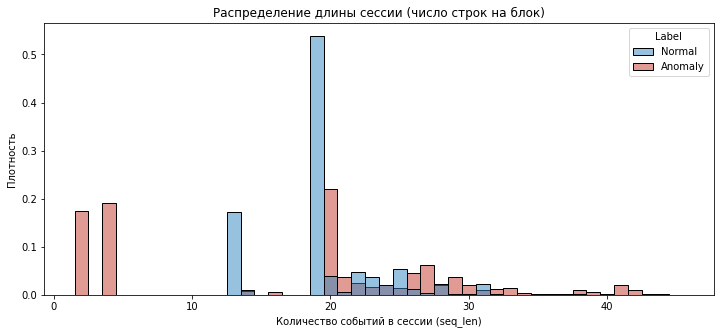

In [4]:
label_path = file_path.parent / "preprocessed" / "anomaly_label.csv"
if not label_path.exists():
    label_path = file_path.parent / "anomaly_label.csv"

labels_df = pd.read_csv(label_path)

sessions_df = pd.DataFrame({
    "BlockId": list(block_total_logs.keys()),
    "seq_len": [block_total_logs[b] for b in block_total_logs],
    "warn_cnt": [block_warn_logs[b] for b in block_total_logs]
})

df = labels_df.merge(sessions_df, on="BlockId", how="inner")

print("Баланс классов в датасете:")
print(df["Label"].value_counts(normalize=True).mul(100).round(2).astype(str) + "%")

plt.figure(figsize=(12, 5))
sns.histplot(
    data=df[df["seq_len"] <= 45], x="seq_len", hue="Label",
    palette={"Normal": "#2e86c1", "Anomaly": "#c0392b"},
    stat="density", common_norm=False, discrete=True, alpha=0.5
)
plt.title("Распределение длины сессии (число строк на блок)")
plt.xlabel("Количество событий в сессии (seq_len)")
plt.ylabel("Плотность")
plt.show()

<div class="alert alert-block alert-warning">
<b> Дисбаланс классов:</b><br>
В данных присутствует  дисбаланс. При обучении модели потребуется применение методов сэмплинга или взвешивания классов. Также график показывает, что аномальные сессии часто имеют нестандартную длину.
</div>

## 4. Бизнес-инсайты: Анализ компонентов и узлов кластера
Где именно происходят сбои? Посмотрим на распределение ошибок по системным компонентам и физическим серверам (IP-адресам).

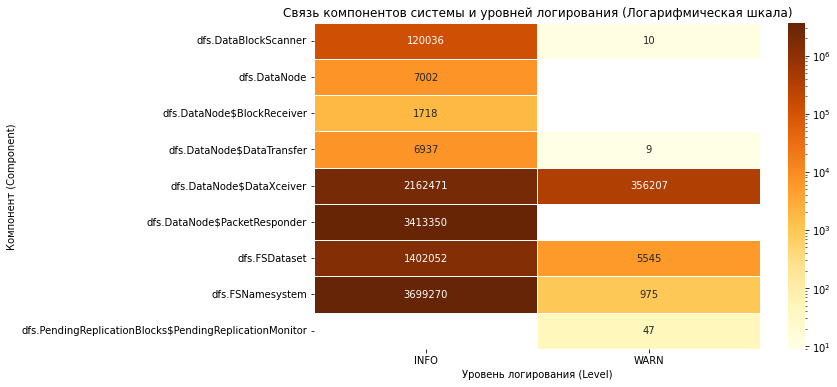

In [5]:
comp_level_df = pd.DataFrame([
    {"Component": comp, "Level": lvl, "Count": count} 
    for (comp, lvl), count in comp_level_counts.items()
])
pivot_df = comp_level_df.pivot(index="Component", columns="Level", values="Count").fillna(0)

plt.figure(figsize=(10, 6))

sns.heatmap(pivot_df, annot=True, fmt=".0f", cmap="YlOrBr", linewidths=.5, norm=LogNorm())
plt.title("Связь компонентов системы и уровней логирования (Логарифмическая шкала)")
plt.xlabel("Уровень логирования (Level)")
plt.ylabel("Компонент (Component)")
plt.show()

###  Выводы по архитектуре системы
* Ошибки уровня `WARN` и выше генерируются преимущественно компонентом **`BlockReceiver`**. 
* Основной объем штатной работы (`INFO`) ложится на `DataXceiver` и `FSNamesystem`. Модели машинного обучения стоит уделять особое внимание событиям от `BlockReceiver`.

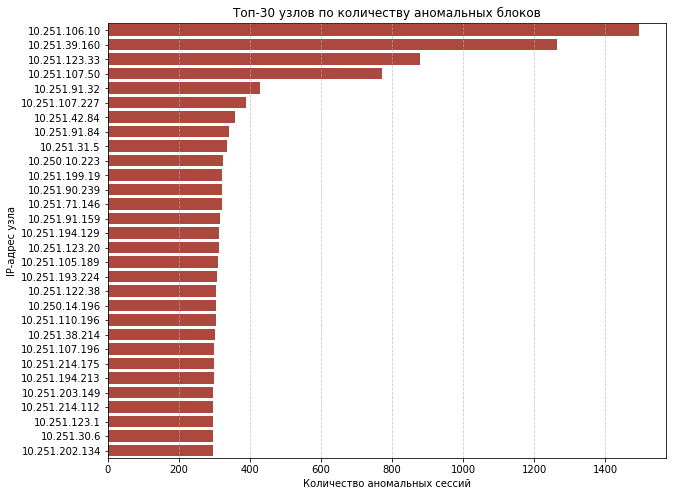

In [6]:
node_rows = []
for ip, blocks in node_blocks.items():
    anomaly_blocks = df[(df["BlockId"].isin(blocks)) & (df["Label"] == "Anomaly")].shape[0]
    node_rows.append({
        "node_ip": ip,
        "total_blocks": len(blocks),
        "anomaly_blocks": anomaly_blocks,
        "anomaly_rate": anomaly_blocks / len(blocks) if len(blocks) > 0 else 0
    })

nodes_df = pd.DataFrame(node_rows).sort_values("anomaly_blocks", ascending=False)

plt.figure(figsize=(10, 8)) 
sns.barplot(
    data=nodes_df.head(30), 
    x="anomaly_blocks",  
    y="node_ip",        
    color="#c0392b"
)
plt.title("Топ-30 узлов по количеству аномальных блоков")
plt.xlabel("Количество аномальных сессий")
plt.ylabel("IP-адрес узла")
plt.grid(axis='x', linestyle='--', alpha=0.7) 
plt.show()

<div class="alert alert-block alert-danger">
<b> Аппаратная локализация сбоев:</b><br>
Аномалии не распределены по кластеру равномерно. Топ-5 узлов  аккумулируют значительную долю всех сбоев системы. Это прямо указывает на возможные проблемы с конкретными физическими серверами или сетевыми свитчами, а не на ошибку в коде HDFS.
</div>